# PINN vanilla per Black-Scholes

**Obiettivo**: addestrare una rete neurale V_θ(τ, S) che soddisfi il residuo
R[V_θ] ≈ 0 e la condizione iniziale V_θ(0, S) = payoff(S), **senza** conoscere
la formula chiusa.

**Architettura**: MLP (2 input → 4 hidden layers × 64 → 1 output), tanh.

**Loss**: L = λ_PDE · MSE(R[V_θ]) + λ_IC · MSE(V_θ(0,S) - payoff) + λ_BC · MSE(BC)

**Validazione**: RMSE contro BS su griglia (τ, S) ∈ (0, T) × (50, 150).

**Nota**: questa è la versione *soft constraints*. In M5b sostituiremo con hard
constraints (Ansatz) per eliminare il tuning dei pesi.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

RESULTS = Path('/content/drive/MyDrive/PINN_option/results')
RESULTS.mkdir(parents=True, exist_ok=True)

S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.2
S_max = 2.0 * K
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Mounted at /content/drive
Device: cpu


In [2]:
def bs_call_np(S, K, tau, r, sigma):
    """BS in time-to-maturity tau. tau=0 → payoff."""
    S = np.asarray(S, dtype=float)
    tau = np.asarray(tau, dtype=float)
    tiny = tau < 1e-12
    tau_safe = np.where(tiny, 1.0, tau)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*tau_safe) / (sigma*np.sqrt(tau_safe))
    d2 = d1 - sigma*np.sqrt(tau_safe)
    price = S*norm.cdf(d1) - K*np.exp(-r*tau_safe)*norm.cdf(d2)
    return np.where(tiny, np.maximum(S-K, 0.0), price)

In [3]:
class PINN(nn.Module):
    """MLP (tau, S) → V. Scaling degli input per condizionamento."""
    def __init__(self, hidden=64, layers=4):
        super().__init__()
        self.register_buffer('tau_scale', torch.tensor(1.0 / T, dtype=torch.float32))
        self.register_buffer('S_scale',   torch.tensor(2.0 / S_max, dtype=torch.float32))
        self.register_buffer('S_shift',   torch.tensor(-1.0, dtype=torch.float32))
        self.register_buffer('V_scale',   torch.tensor(10.0, dtype=torch.float32))

        net = [nn.Linear(2, hidden), nn.Tanh()]
        for _ in range(layers - 1):
            net += [nn.Linear(hidden, hidden), nn.Tanh()]
        net += [nn.Linear(hidden, 1)]
        self.net = nn.Sequential(*net)

    def forward(self, tau, S):
        # Input scaled
        tau_n = tau * self.tau_scale
        S_n   = S * self.S_scale + self.S_shift
        x = torch.cat([tau_n, S_n], dim=1)
        # Output scaled back
        return self.net(x) * self.V_scale

In [4]:
def pde_residual(model, tau, S):
    """R[V_θ] con la convenzione di M1 (tau = time-to-maturity)."""
    tau = tau.clone().requires_grad_(True)
    S   = S.clone().requires_grad_(True)

    V = model(tau, S)

    dV_dtau = torch.autograd.grad(V, tau, torch.ones_like(V), create_graph=True)[0]
    dV_dS   = torch.autograd.grad(V, S,   torch.ones_like(V), create_graph=True)[0]
    d2V_dS2 = torch.autograd.grad(dV_dS, S, torch.ones_like(dV_dS), create_graph=True)[0]

    return dV_dtau - 0.5*sigma**2*S**2*d2V_dS2 - r*S*dV_dS + r*V

In [10]:
def train_pinn(model, n_epochs=20000, n_pde=3000, n_ic=400, n_bc=400,
               lr=1e-3, lambda_pde=1.0, lambda_ic=10.0, lambda_bc=10.0,
               verbose_every=2000):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs, eta_min=1e-5)

    history = []

    for epoch in range(1, n_epochs + 1):
        model.train()


        n_pde_unif = n_pde // 2
        n_pde_kink = n_pde - n_pde_unif

        tau_unif = torch.rand(n_pde_unif, 1, device=device) * T
        S_unif   = torch.rand(n_pde_unif, 1, device=device) * S_max


        tau_kink = torch.rand(n_pde_kink, 1, device=device) * 0.3 * T
        S_kink   = K + torch.randn(n_pde_kink, 1, device=device) * 10.0
        S_kink   = S_kink.clamp(1.0, S_max - 1.0)

        tau_pde = torch.cat([tau_unif, tau_kink])
        S_pde   = torch.cat([S_unif, S_kink])


        n_ic_unif = n_ic // 2
        n_ic_kink = n_ic - n_ic_unif

        S_ic_unif = torch.rand(n_ic_unif, 1, device=device) * S_max
        S_ic_kink = K + torch.randn(n_ic_kink, 1, device=device) * 5.0
        S_ic_kink = S_ic_kink.clamp(1.0, S_max - 1.0)

        S_ic = torch.cat([S_ic_unif, S_ic_kink])
        tau_ic = torch.zeros_like(S_ic)
        V_ic_true = torch.clamp(S_ic - K, min=0.0)

        # Boundary
        tau_bc = torch.rand(n_bc, 1, device=device) * T
        S_bc_left  = torch.zeros_like(tau_bc)
        S_bc_right = torch.full_like(tau_bc, S_max)
        V_bc_left_true  = torch.zeros_like(tau_bc)
        V_bc_right_true = S_bc_right - K * torch.exp(-r * tau_bc)

        # Loss
        res = pde_residual(model, tau_pde, S_pde)
        L_pde = (res**2).mean()

        V_ic_pred = model(tau_ic, S_ic)
        L_ic = ((V_ic_pred - V_ic_true)**2).mean()

        V_bc_left  = model(tau_bc, S_bc_left)
        V_bc_right = model(tau_bc, S_bc_right)
        L_bc = ((V_bc_left - V_bc_left_true)**2).mean() + \
               ((V_bc_right - V_bc_right_true)**2).mean()

        loss = lambda_pde * L_pde + lambda_ic * L_ic + lambda_bc * L_bc

        opt.zero_grad()
        loss.backward()
        opt.step()
        scheduler.step()

        history.append({'epoch': epoch, 'loss': loss.item(),
                        'L_pde': L_pde.item(), 'L_ic': L_ic.item(), 'L_bc': L_bc.item()})

        if epoch % verbose_every == 0 or epoch == 1:
            print(f"ep {epoch:5d} | lr={scheduler.get_last_lr()[0]:.1e} | loss={loss.item():.3e} | "
                  f"pde={L_pde.item():.2e} | ic={L_ic.item():.2e} | bc={L_bc.item():.2e}")

    return history

In [11]:
model = PINN(hidden=64, layers=4)
history = train_pinn(model, n_epochs=10000, n_pde=2000, n_ic=200, n_bc=200,
                     lr=1e-3, lambda_pde=1.0, lambda_ic=10.0, lambda_bc=10.0)

ep     1 | lr=1.0e-03 | loss=1.166e+05 | pde=1.16e-02 | ic=1.26e+03 | bc=1.04e+04
ep  2000 | lr=9.1e-04 | loss=6.617e+00 | pde=1.47e+00 | ic=4.92e-01 | bc=2.32e-02
ep  4000 | lr=6.6e-04 | loss=4.313e+00 | pde=9.42e-01 | ic=3.21e-01 | bc=1.58e-02
ep  6000 | lr=3.5e-04 | loss=3.223e+00 | pde=7.74e-01 | ic=2.41e-01 | bc=4.04e-03
ep  8000 | lr=1.0e-04 | loss=2.600e+00 | pde=6.02e-01 | ic=1.95e-01 | bc=4.46e-03
ep 10000 | lr=1.0e-05 | loss=2.285e+00 | pde=6.05e-01 | ic=1.67e-01 | bc=1.22e-03


In [12]:
@torch.no_grad()
def evaluate_grid(model, n_tau=50, n_S=50):
    tau_g = torch.linspace(0.01, 0.99*T, n_tau, dtype=torch.float32, device=device)
    S_g   = torch.linspace(0.5*K, 1.5*K, n_S, dtype=torch.float32, device=device)
    TAU, S = torch.meshgrid(tau_g, S_g, indexing='ij')
    tau_flat = TAU.reshape(-1, 1)
    S_flat   = S.reshape(-1, 1)
    V_pred = model(tau_flat, S_flat).cpu().numpy().reshape(n_tau, n_S)
    V_true = bs_call_np(S.cpu().numpy(), K, TAU.cpu().numpy(), r, sigma)
    rmse = np.sqrt(np.mean((V_pred - V_true)**2))
    max_err = np.max(np.abs(V_pred - V_true))
    return TAU.cpu().numpy(), S.cpu().numpy(), V_pred, V_true, rmse, max_err


TAU, S, V_pred, V_true, rmse, max_err = evaluate_grid(model)
print(f"RMSE vs BS:   {rmse:.4e}")
print(f"Max error:    {max_err:.4e}")

V_at_T_K = model(torch.tensor([[T]], device=device),
                 torch.tensor([[K]], device=device)).item()
print(f"V(τ=T, S=K) = {V_at_T_K:.6f}  (BS: 10.450584)")

RMSE vs BS:   1.8224e-01
Max error:    6.4333e-01
V(τ=T, S=K) = 10.132883  (BS: 10.450584)


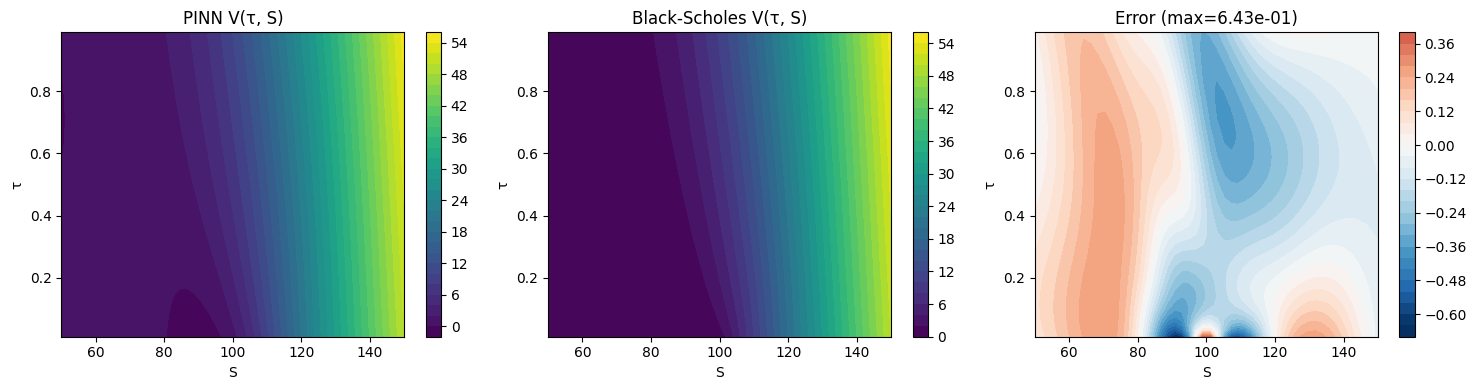

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# PINN
im0 = axes[0].contourf(S[0], TAU[:, 0], V_pred, 30, cmap='viridis')
axes[0].set_title('PINN V(τ, S)'); axes[0].set_xlabel('S'); axes[0].set_ylabel('τ')
plt.colorbar(im0, ax=axes[0])

# BS
im1 = axes[1].contourf(S[0], TAU[:, 0], V_true, 30, cmap='viridis')
axes[1].set_title('Black-Scholes V(τ, S)'); axes[1].set_xlabel('S'); axes[1].set_ylabel('τ')
plt.colorbar(im1, ax=axes[1])

# Error
err = V_pred - V_true
im2 = axes[2].contourf(S[0], TAU[:, 0], err, 30, cmap='RdBu_r',
                      vmin=-max_err, vmax=max_err)
axes[2].set_title(f'Error (max={max_err:.2e})'); axes[2].set_xlabel('S'); axes[2].set_ylabel('τ')
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.savefig(RESULTS / "m5a_pinn_vs_bs.png", dpi=150)
plt.show()

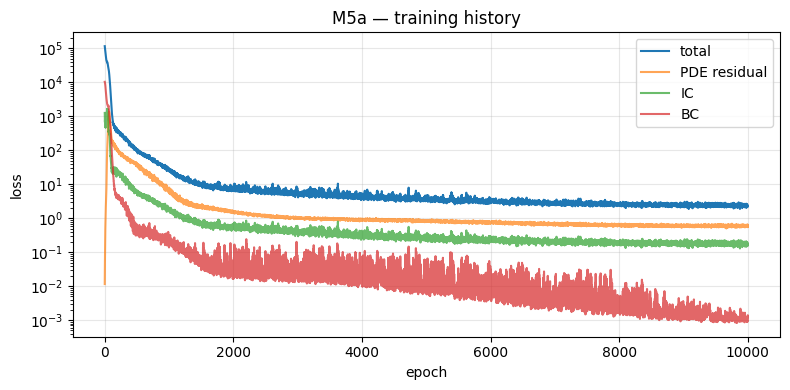

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
epochs  = [h['epoch'] for h in history]
ax.semilogy(epochs, [h['loss']  for h in history], label='total')
ax.semilogy(epochs, [h['L_pde'] for h in history], label='PDE residual', alpha=0.7)
ax.semilogy(epochs, [h['L_ic']  for h in history], label='IC', alpha=0.7)
ax.semilogy(epochs, [h['L_bc']  for h in history], label='BC', alpha=0.7)
ax.set_xlabel('epoch'); ax.set_ylabel('loss'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('M5a — training history')
plt.tight_layout()
plt.savefig(RESULTS / "m5a_loss_history.png", dpi=150)
plt.show()